# **Taller páctico**


---



In [63]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

ruta_csv = '/content/drive/MyDrive/Taller 4 - Aprendizaje No Supervisado/steam-200k.csv'
df = pd.read_csv(ruta_csv, header=None, names=['user_id', 'game_name', 'behavior', 'hours_played', '0'])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **1. Exploración de los datos**


---


Análisis exploratorio del conjunto de datos


In [64]:
# Visualización previa

print(df.head())

     user_id                   game_name  behavior  hours_played  0
0  151603712  The Elder Scrolls V Skyrim  purchase           1.0  0
1  151603712  The Elder Scrolls V Skyrim      play         273.0  0
2  151603712                   Fallout 4  purchase           1.0  0
3  151603712                   Fallout 4      play          87.0  0
4  151603712                       Spore  purchase           1.0  0


In [65]:
print(df.shape)

(200000, 5)


In [66]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   user_id       200000 non-null  int64  
 1   game_name     200000 non-null  object 
 2   behavior      200000 non-null  object 
 3   hours_played  200000 non-null  float64
 4   0             200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB
None


In [67]:
# Valores nulos

print(df.isnull().sum())

# No hay valores nulos

user_id         0
game_name       0
behavior        0
hours_played    0
0               0
dtype: int64


In [68]:
# Duplicados

print('Valores duplicados:',df.duplicated().sum())

# Se identificaron 707 valores duplicado, se borrarán estos registros

df = df.drop_duplicates()
print('Después de la limpieza, los valores duplicados son:',df.duplicated().sum())

Valores duplicados: 707
Después de la limpieza, los valores duplicados son: 0


In [83]:
df_play = df[df['behavior'] == 'play'].copy()
print(df_play.describe().round(2))

            user_id  hours_played
count  7.048900e+04      70489.00
mean   1.058812e+08         48.88
std    7.150365e+07        229.34
min    5.250000e+03          0.10
25%    4.934256e+07          1.00
50%    9.169067e+07          4.50
75%    1.556738e+08         19.10
max    3.099031e+08      11754.00


In [70]:
# La ultima columna nombrada 0, tiene en todas las filas continee el valor 0, como no representa ninguna metrica real
# como precio, algún identificador y ninguna fecha, lo mejor es eliminarla para mantener el DF limpio y optimizado

df = df.drop(columns=['0'])
print(df.head())

     user_id                   game_name  behavior  hours_played
0  151603712  The Elder Scrolls V Skyrim  purchase           1.0
1  151603712  The Elder Scrolls V Skyrim      play         273.0
2  151603712                   Fallout 4  purchase           1.0
3  151603712                   Fallout 4      play          87.0
4  151603712                       Spore  purchase           1.0


**Visualizaciones para conprender la información**

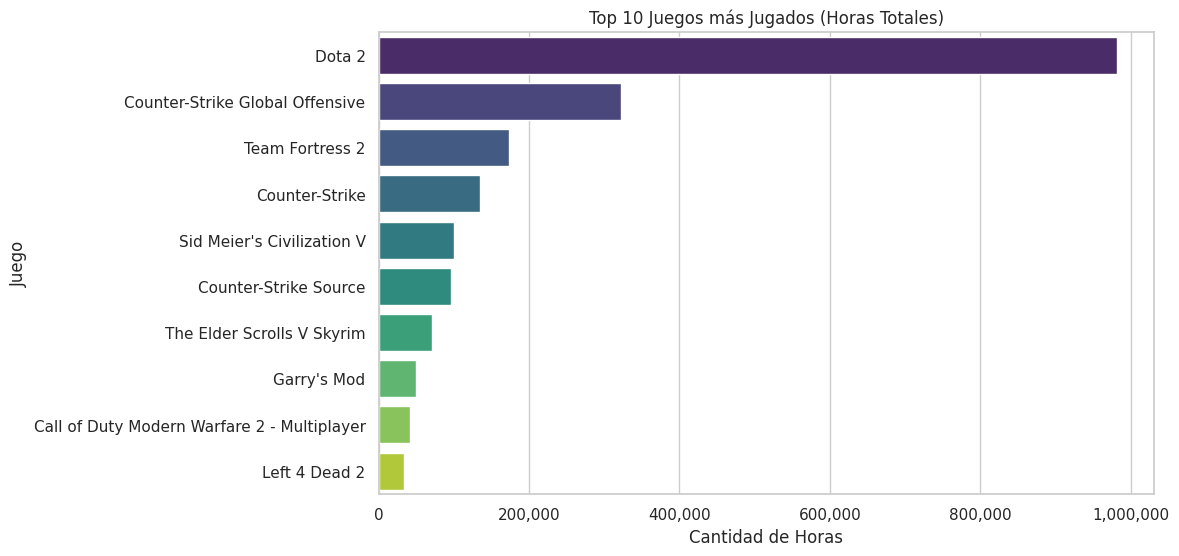

In [71]:
# Los juegos más jugados
"""
En este dataset de Steam, la columna 'behavior' clasifica el tipo de interacción que el usuario tuvo o tiene con el juego.
Purchase indica que el juego fue agregado a la biblioteca del usuario, por eso en horas_jugadas se tiene un valor de 1. Es decir, el usuario solo hizo la compra del juego.
Por otro lado Play indica que el usuario instaló y ejecutó el juego, por ende para encontrar los juegos más jugados usaremos solo los registros de Play.
"""
df_play = df[df['behavior'] == 'play']
top_juegos = df_play.groupby('game_name')['hours_played'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_juegos.values, y=top_juegos.index, hue=top_juegos.index, palette='viridis', legend=False)
plt.title('Top 10 Juegos más Jugados (Horas Totales)')
plt.xlabel('Cantidad de Horas')
plt.ylabel('Juego')
plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.show()

**Conclusión 1**


---


Se nota con bastante diferencia que el top 1, Dota 2 de los juegos más jugados supera a los demás, alcanzando casi un millón de horas, seguido Conter-Strike Global Offensive con casi 400,000 horas.
En cualquier caso, se logra evidenciar que los juegos más jugados en Steam son de estrategia, acción, disparos y aventura, destacando que Counter-Strike cuenta con 3 títulos diferentes en el top 10, 2 de ellos son viejitos pero se mantienen con usuarios fieles a la saga.





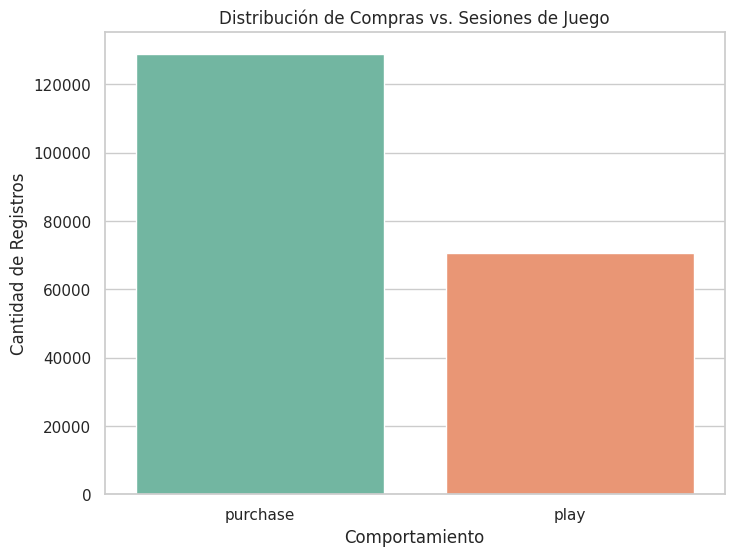

In [72]:
# Distribución de comportamiento (Purchase vs Play)

plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='behavior', hue='behavior', palette='Set2', legend=False)
plt.title('Distribución de Compras vs. Sesiones de Juego')
plt.xlabel('Comportamiento')
plt.ylabel('Cantidad de Registros')
plt.show()

In [73]:
print(df["behavior"].value_counts())

behavior
purchase    128804
play         70489
Name: count, dtype: int64


**Conclusión 2**


---
Hay personas que pueden comprar el juego por el hype pero nunca prueban los juegos, también hay personas que adquieren algún juego por hobbie, al estilo coleccionista y nunca prueban los títulos, y se evidencia que hay más personas así que los que relamente dedican algunas horas a probar y jugar cualquier título, en este dataset de Steam las perosnas que solo adquieren un juego casi doble a las personas que realmente si juegan. Es bueno aclarar que hay usuarios con más de un solo juego jugado o adquirido.


# **2. Preparación de los datos**

---

1. Se hará un filtro exclusivo de horas jugadas reales, es decir, solo usaremos a los usuarios que realmente han dedicado horas verificables en la plataforma de Steam, debido a que, los registros de "purchase" siempre marcan 1.0 en la columna de horas jugadas, funciona más como un booleano al decir que si tienen el juego, pero al mezclar este indicador con las horas reales de juego crearía ruido estatico, lo cual puede confundir al modelo al tratar a las los "purchase" como una unidad de medida.
2. La siguiente forma de preparar los datos, es agrupar el df por el user_id, para crear métricas númericxas por cada jugaro; horas totales jugadas, cantidad de juegos probados y promedio de horas jugadas. Por medio de Clustering va a agrupar y comprar entre sí. El formato original no sirve porque divide al usuario en múltiples filas por cada juego. Al consolidar la información, creamos un "perfil gamer" único por fila, permitiendo que el modelo detecte patrones (jugadores pro, jugadores casuales, jugadores actuales, coleccionistas, etc).

In [74]:
# Filtro de jugadores reales

df_play = df[df['behavior'] == 'play'].copy()

# Agrupación por usuario

perfil_usuario = df_play.groupby('user_id').agg(
    horas_jugadas_totales=('hours_played', 'sum'),
    cantidad_juegos_probados=('game_name', 'nunique'),
    promedio_horas_jugadas=('hours_played', 'mean')
).reset_index()

perfil_usuario['promedio_horas_jugadas'] = perfil_usuario['promedio_horas_jugadas'].round(2)

print(df_play.head())
print('\nCantidad de registros del perfil de usuario: ',perfil_usuario.shape)

print("\nAgrupación de usuarios:\n", perfil_usuario.head())

     user_id                   game_name behavior  hours_played
1  151603712  The Elder Scrolls V Skyrim     play         273.0
3  151603712                   Fallout 4     play          87.0
5  151603712                       Spore     play          14.9
7  151603712           Fallout New Vegas     play          12.1
9  151603712               Left 4 Dead 2     play           8.9

Cantidad de registros del perfil de usuario:  (11350, 4)

Agrupación de usuarios:
    user_id  horas_jugadas_totales  cantidad_juegos_probados  \
0     5250                  225.5                         6   
1    76767                 1227.0                        20   
2    86540                  255.0                        15   
3   144736                    0.1                         1   
4   181212                    2.2                         2   

   promedio_horas_jugadas  
0                   37.58  
1                   61.35  
2                   17.00  
3                    0.10  
4            

# **3. Modelado**


---

El algoritmo de Clustering seleccionado es **K-Means**.

K-Means es altamente eficiente procesando miles de registros, como es el caso del dataframe de Steam. por otro lado, K-Means agrupa por segmentos cada valor y no los descarta al ser valores 'atípicos' que en mi dataframe solo muestran a jugadores con muchas más horas que otros, y en este ecosistema no son errores, sino se describen como 'hardcore gamers'. Y por último, K-Means genera centroides que son promedios exactos, lo cual, permite extraer datos reales de horas y cantidad de juegos para así poder perfil o separar a cada grupo de jugadores.

In [75]:

from sklearn.preprocessing import MinMaxScaler

# No se usa user_id porque es solo un identificador de un usuario
columnas_numericas = ['horas_jugadas_totales', 'cantidad_juegos_probados', 'promedio_horas_jugadas']

scaler = MinMaxScaler()
perfil_usuario_scaled = pd.DataFrame(scaler.fit_transform(perfil_usuario[columnas_numericas]))



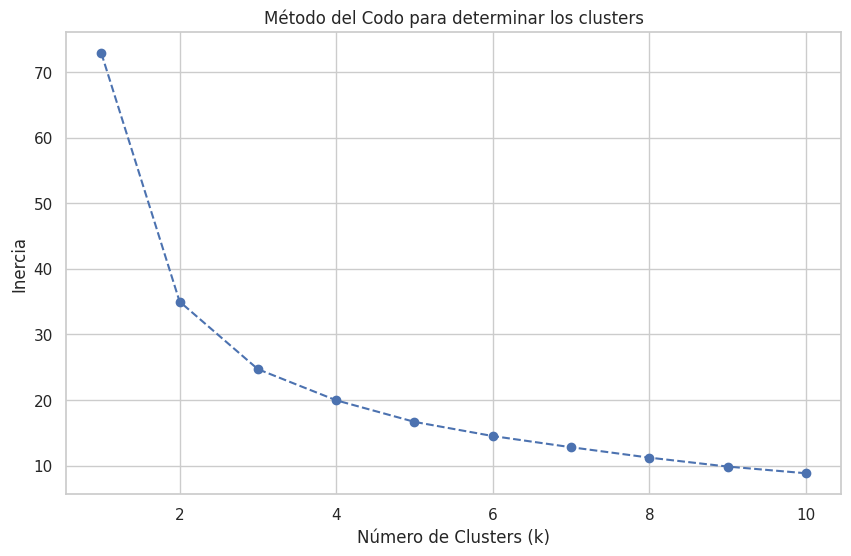

In [76]:
from sklearn.cluster import KMeans

X = perfil_usuario_scaled.values

# Se hace el método del codo para concer el número de clústers

inercias = []
rango_k = range(1,11)

for k in rango_k:
  kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans_temp.fit(X)
  inercias.append(kmeans_temp.inertia_)

plt.figure(figsize=(10,6))
plt.plot(rango_k, inercias, marker='o', linestyle='--')
plt.title('Método del Codo para determinar los clusters')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inercia')
plt.show()

In [77]:
# Basados en el método del codo se usan los clusters 2, 3 y 4 para comparar como se segmentan los grupos

for k in [2, 3, 4]:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(
        perfil_usuario_scaled.values
    )

    # Asociar los grupos con los datos originales
    df_perfiles = perfil_usuario[columnas_numericas].copy()
    df_perfiles['cluster'] = etiquetas

    resumen = df_perfiles.groupby('cluster').agg(
        cantidad_usuarios=('horas_jugadas_totales', 'size'),
        horas_totales_promedio=('horas_jugadas_totales', 'mean'),
        juegos_probados_promedio=('cantidad_juegos_probados', 'mean'),
        horas_promedio_por_juego=('promedio_horas_jugadas', 'mean')
    ).round(2)

    print(f'\n{"=" * 50}')
    print(f'RESUMEN PARA k = {k}')
    print(resumen)



RESUMEN PARA k = 2
         cantidad_usuarios  horas_totales_promedio  juegos_probados_promedio  \
cluster                                                                        
0                    10709                  148.71                      3.88   
1                      641                 2890.50                     45.12   

         horas_promedio_por_juego  
cluster                            
0                           57.13  
1                          482.42  

RESUMEN PARA k = 3
         cantidad_usuarios  horas_totales_promedio  juegos_probados_promedio  \
cluster                                                                        
0                      187                 4799.02                      63.8   
1                    10103                   91.43                       3.0   
2                     1060                 1532.27                      26.6   

         horas_promedio_por_juego  
cluster                            
0                     

Al evaluar la curva de inercia, el punto de inflexión principal (el 'codo') se define alrededor de $k=4$. A partir de este valor, la reducción en la suma de distancias intra-clúster es marginal, indicando que añadir más agrupaciones no aporta una ganancia significativa en la segmentación del comportamiento de los usuarios.

In [78]:

# En base a los resultados de arriba, lo mejor es usar 4 clústeres, se ven los grupos mejor distribuidos

modelo_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

etiquetas_4 = modelo_4.fit_predict(
    perfil_usuario_scaled.values
)

df_analisis = perfil_usuario.copy()
df_analisis['cluster'] = etiquetas_4

resumen_mediana = df_analisis.groupby('cluster').agg(
    cantidad_usuarios=('user_id', 'nunique'),
    mediana_horas_totales=('horas_jugadas_totales', 'median'),
    mediana_juegos_probados=('cantidad_juegos_probados', 'median'),
    mediana_horas_promedio=('promedio_horas_jugadas', 'median')
).round(2)

print(resumen_mediana)


         cantidad_usuarios  mediana_horas_totales  mediana_juegos_probados  \
cluster                                                                      
0                     9968                   12.0                      1.0   
1                      139                 4855.2                     18.0   
2                      145                 2514.0                    100.0   
3                     1098                 1233.6                     10.0   

         mediana_horas_promedio  
cluster                          
0                          7.25  
1                        280.68  
2                         22.62  
3                        141.44  


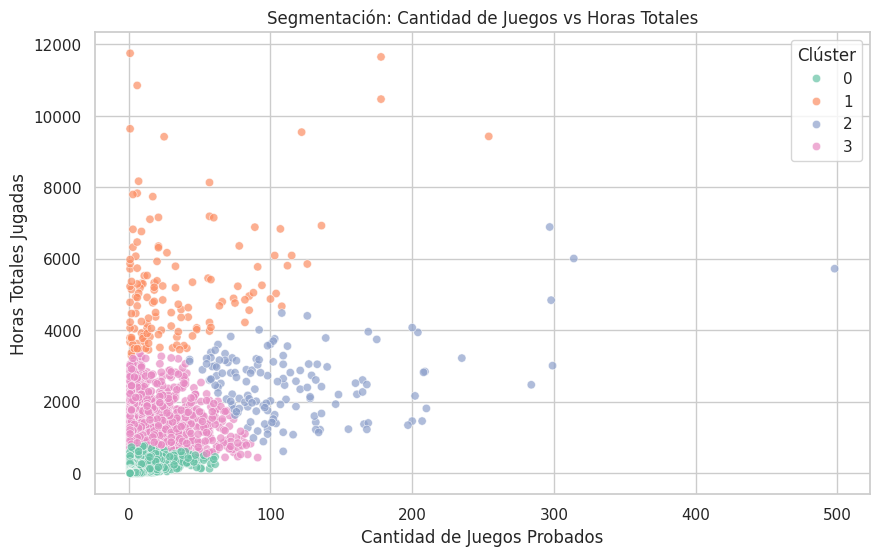

In [82]:
# Diagrama de dispersión

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_analisis,
    x='cantidad_juegos_probados',
    y='horas_jugadas_totales',
    hue='cluster',
    palette='Set2',
    alpha=0.7
)
plt.title('Segmentación: Cantidad de Juegos vs Horas Totales')
plt.xlabel('Cantidad de Juegos Probados')
plt.ylabel('Horas Totales Jugadas')
plt.legend(title='Clúster')
plt.show()

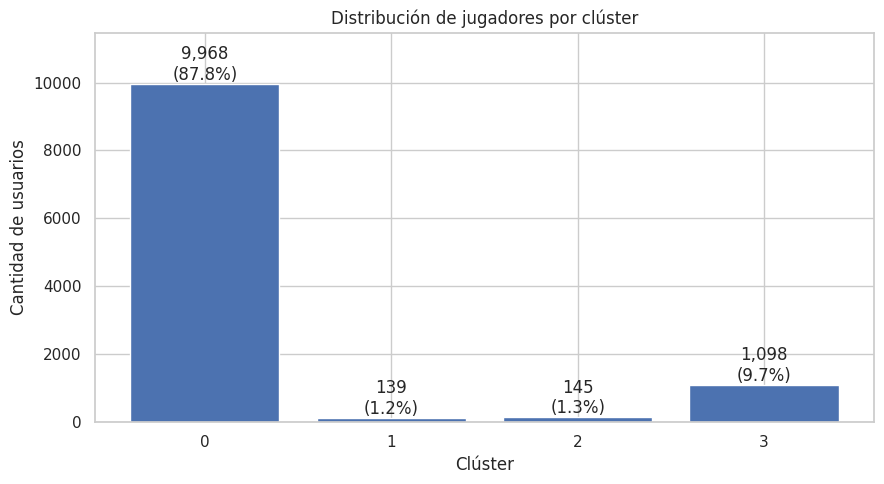

In [80]:
# Resumen de usuarios por clúster
conteo_clusters = (
    df_analisis['cluster']
    .value_counts()
    .sort_index()
)

porcentaje_clusters = conteo_clusters / conteo_clusters.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    conteo_clusters.index.astype(str),
    conteo_clusters.values
)

ax.set_title('Distribución de jugadores por clúster')
ax.set_xlabel('Clúster')
ax.set_ylabel('Cantidad de usuarios')

for barra, porcentaje in zip(barras, porcentaje_clusters):
    altura = barra.get_height()
    ax.annotate(
        f'{int(altura):,}\n({porcentaje:.1f}%)',
        (barra.get_x() + barra.get_width() / 2, altura),
        ha='center',
        va='bottom'
    )

ax.set_ylim(0, conteo_clusters.max() * 1.15)
plt.tight_layout()
plt.show()


# **4. Interpretación de los Clusters**

---



1.   **Clúster 0 - Jugadores de baja actividad (Casuales)**: Es el segmento mayoritario como se puede evidenciar, el usuario común de este grupo han jugado pocas horas y han probado por lo general un solo juego, es un grupo que entra a Steam esporádicamente y son personas que compran muy poco.
2.   **Clúster 1 - Jugadores Intesivos (Hardcore):**: Son usuarios con una dedicación acumulada muy alta, lo que refleja que tienen bastantes horas de juego, no prueban muchos juegos, a excepción de algunos, pero si dedican muchas horas a sus juegos favoritos.
3. **Clúster 2 - Exploradores de juegos (Coleccionistas)**: Este grupo destaca principalmente por la cantidad de juegos en su biblioteca (tienen una mediana de 100 juegos probados), pero no dedican tantas horas en general a un solo juego, se prodría decir que son usuarios que saltan rápidamente entre juegos, también se puede afirmar que son usuarios que les gusta tener mucha variedad de juegos, son el público ideal para los descuentos de Steam, aunque rara vez completan o rescantan en su totalidad algún juego.
4. **Clúster 3 - Jugadores habituales**: Es un grupo sílido, con un balance excelente, son jugadores que dedican su tiempo libre a un par de juegos, es decir, son jugadores que se pasan un juego completo a su tiempo y después de completarlo sigue con otro juego, puede ser de la misma saga o de la misma tematica, puede considerarse como un jugador lineal, hace compras regulares. En lo personal, me identifico con este grupo de usuarios, que dedican su tiempo libre o de osio con un juego de sus favoritos, o que se mantiene fiel a una saga y cambia de juego cuando sale la continuanción de un juego.


---

En resumen, los gruato grupos son diferentes en todos los sentidos, en la dedicación y cantidad de juegos jugados, es válido aclarar que hay algunas excepciones, pero son grupos que al menos si juegan algunos juegos, por eso se hizo la separación entre la categoria de comportamiento ('behavior') entre los usuarios que si juegan ('play') y los que solo compran ('purchase'), por eso es un análisis real entre los jugadores que dedican pocas horas hasta los que dedican todo su tiempo a sus juegos favoritos.  



# **5. Recomendaciones de negocio**


---


1.   **Estrategia de marketing:**


*   **Jugadores Casuales (Clúster 0):** Implementar campañas de reactivación y descubrimiento, con recomendaciones de juegos accesibles y experiencias cortas. Es decir, descuentos en juegos, ofertas y recomendaciones personalizadas según su historial de juegos y acceso a demos para que prueben los juegos.
*   **Especialistas Hardcore (Clúster 1):** Ofrecer recomendaciones de expansiones, contenido adicional (DLC), secuelas y juegos relacionados con los títulos que ya disfrutan. La cantidad de horas dedicadas a jugar sugiere una dedicación abundante, aunque no demuestra que gasten más dinero, pueden jugar juegos play-to-free, así que se pueden hacer descuentos a juegos similares de su preferencia, hacer ofertas en secuelas o títulos nuevos y acceso anticipado a eventos o pruebas de contenido cuando esté disponible.
*   **Coleccionistas y Exploradores (Clúster 2):** Utilizar recomendaciones variadas, listas de novedades y colecciones temáticas. Estos usuarios han probado una gran cantidad de juegos pero presentan menos horas por título, por lo que conviene explorar qué géneros les interesan antes de personalizar las ofertas. Sin embargo, se les puede hacer descuentos a títulos nuevos, acceso anticipado (demos) de juegos que van a salir o que son de su interes.
*   **Jugadores Habituales (Clúster 3):** Recomendar títulos relacionados con los que ya juegan, nuevas entregas de franquicias conocidas y experiencias cooperativas cuando sus preferencias lo respalden. Se les puede dar acceso anticipado (Early Access), secuelas y descuentos personalizados en los mismos géneros que ya tienen en su biblioteca.


2.   **Priorización para campañas de fidelización**: Los esfuerzos de retención y lealtad deben dirigirse principalmente al Clúster 3 (Habituales) y al Clúster 1 (Especialistas). Los jugadores habituales garantizan un flujo de ingresos constante y predecible mediante la compra regular de nuevos lanzamientos a precio completo. Por su parte, los especialistas mantienen vivos los ecosistemas multijugador, asegurando un alto volumen de usuarios activos diarios, por otro lado no se pueden ignorar los otros dos grupos, para el Clúster 2 (Exploradores) ya de por sí son los que más juegos prueba, es decir, son los que quizá más gastan pero no son fieles por decirlo así a un solo juego. Y además, el clúster 0 reúne casi el 88 % de los usuarios. Aunque su tasa de conversión fuera baja, no deberíamos ignorarlo: por su tamaño, incluso una mejora pequeña podría tener un efecto relevante.


3. **Información adicional para optimizar la segmentación:**
* **Datos financieros:** El monto real invertido en dólares o pesos (COP) por usuario, distinguiendo entre la compra del juego base y las microtransacciones in-game.
* **Clasificación de géneros:** Etiquetas específicas de los títulos (RPG, Shooter, Estrategia, Multijugador vs Single-player) para perfilar afinidades de contenido.
* **Comportamiento en el tiempo:** Frecuencia de sesiones por semana, horarios de conexión y tiempo de inactividad desde la última sesión.
* **Factor social:** Tamaño de la lista de amigos, clanes y cantidad de reseñas publicadas, lo que ayudaría a identificar embajadores de marca con capacidad de influir en compras grupales.


